In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!unzip /content/drive/MyDrive/Colab_notebooks/dataset.zip -d "/content/extracted_files"


Archive:  /content/drive/MyDrive/Colab_notebooks/dataset.zip
  inflating: /content/extracted_files/13. Final project/countries.csv  
  inflating: /content/extracted_files/13. Final project/products.csv  
  inflating: /content/extracted_files/13. Final project/events.csv  


In [3]:

import pandas as pd
import numpy as np

# Завантажуємо таблиці
events = pd.read_csv('/content/extracted_files/13. Final project/events.csv')
products = pd.read_csv('/content/extracted_files/13. Final project/products.csv')
countries = pd.read_csv('/content/extracted_files/13. Final project/countries.csv')

# дивимось на розмір кожної таблиці (рядки, колонки)
print(f"Розмір таблиці events: {events.shape}")
print(f"Розмір таблиці products: {products.shape}")
print(f"Розмір таблиці countries: {countries.shape}")

Розмір таблиці events: (1330, 10)
Розмір таблиці products: (12, 2)
Розмір таблиці countries: (249, 5)


In [4]:
# Огляд таблиці товарів
print("--- Інформація про products.csv ---")
products.info()
print(products.head())

# Огляд таблиці країн
print("\n--- Інформація про countries.csv ---")
countries.info()
print(countries.head())

# Огляд таблиці подій (продажів)
print("\n--- Інформація про events.csv ---")
events.info()
print(events.head())

--- Інформація про products.csv ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes
     id        item_type
0  2103           Cereal
1  7940        Household
2  2455          Clothes
3  1270        Beverages
4  8681  Office Supplies

--- Інформація про countries.csv ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     248 non-null    object
 2   alpha-3     249 non-null    object
 3   region      248 non-null    object
 4   sub-region  248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB
             name alpha-2 alpha-3   reg

Аналіз поточного стану даних :
​Пропуски (Missing Values):
​В products.csv — усе чисто (усі 12 рядків заповнені).
​В countries.csv — є по 1 пропуску в alpha-2, region та sub-region (248 non-null замість 249).
​В events.csv — критично! У колонці Country Code є лише 1248 значень із 1330 (тобто 82 пропуски). Також є 2 пропуски в Units Sold (1328 замість 1330).
​Невідповідність типів даних (Data Types):
​В events.csv колонки Order Date та Ship Date розпізналися як object (текст). Для аналізу динаміки та розрахунку інтервалів часу їх обов'язково треба перетворити на формат дат (datetime).
​Колонка Units Sold (кількість проданого товару) має тип float64 (дробове число). Оскільки штучний товар зазвичай продається цілими одиницями, логічно буде перевести його в int після обробки пропусків.

In [5]:
# Рахуємо пропуски у відсотках для таблиці events
missing_events = events.isnull().sum()
missing_percent = (events.isnull().sum() / len(events)) * 100

# Зведемо в одну табличку для зручності
missing_df = pd.DataFrame({'Кількість пропусків': missing_events, 'Частка (%)': missing_percent})
print(missing_df[missing_df['Кількість пропусків'] > 0])


              Кількість пропусків  Частка (%)
Country Code                   82    6.165414
Units Sold                      2    0.150376


Units Sold (2 пропуски, ~0.15%): Частка мізерна. Ми не можемо прогнозувати, скільки саме штук було продано, а заміна середнім чи медіаною може викривити фінансові показники. Оскільки це транзакційні дані, найкраще рішення — видалити ці 2 рядки.
​Country Code (82 пропуски, ~6.16%): Понад 6% — це забагато для простого видалення, адже ми втратимо фінансові дані (дохід, ціну, кількість). Проте, у нас немає додаткових маркерів (наприклад, IP-адрес чи міст), щоб відновити країну. Оскільки в подальшому ми аналізуватимемо продажі в розрізі географії, ми можемо замінити ці пропуски на строкове значення 'Unknown' (Невідомо). Це дозволить зберегти грошові метрики для загального аналізу і водночас виділити ці замовлення в окрему категорію при аналізі країн.

In [6]:
# 1. Видаляємо рядки, де пропущено Units Sold
events = events.dropna(subset=['Units Sold'])

# 2. Заповнюємо пропуски в Country Code значенням 'Unknown'
events['Country Code'] = events['Country Code'].fillna('Unknown')

# Перевіряємо, чи зникли пропуски в events
print("Залишилося пропусків в events:", events.isnull().sum().sum())

Залишилося пропусків в events: 0


In [7]:
# Перетворюємо дати
events['Order Date'] = pd.to_datetime(events['Order Date'])
events['Ship Date'] = pd.to_datetime(events['Ship Date'])

# Перетворюємо Units Sold на ціле число
events['Units Sold'] = events['Units Sold'].astype(int)

# Перевіримо результат
print(events[['Order Date', 'Ship Date', 'Units Sold']].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
Units Sold             int64
dtype: object


In [8]:
# Отримаємо описову статистику для числових колонок
print(events[['Units Sold', 'Unit Price', 'Unit Cost']].describe())

        Units Sold   Unit Price    Unit Cost
count  1328.000000  1328.000000  1328.000000
mean   4952.201807   264.913245   187.211521
std    2905.198996   217.386320   176.187801
min       2.000000     9.330000     6.920000
25%    2356.750000    81.730000    35.840000
50%    4962.000000   154.060000    97.440000
75%    7459.500000   437.200000   263.330000
max    9999.000000   668.270000   524.960000


In [9]:
events.describe()

,Order ID,Order Date,Ship Date,Product ID,Units Sold,Unit Price,Unit Cost
count,1.328000e+03,1328,1328,1328.000000,1328.000000,1328.000000,1328.000000
mean,5.416231e+08,2013-10-11 22:28:54.939759104,2013-11-05 17:22:02.891566336,5787.775602,4952.201807,264.913245,187.211521
min,1.006406e+08,2010-01-01 00:00:00,2010-01-10 00:00:00,1270.000000,2.000000,9.330000,6.920000
25%,3.213291e+08,2011-12-14 06:00:00,2012-01-02 00:00:00,3127.000000,2356.750000,81.730000,35.840000
50%,5.399925e+08,2013-10-15 12:00:00,2013-11-05 12:00:00,5988.000000,4962.000000,154.060000,97.440000
75%,7.547357e+08,2015-08-29 12:00:00,2015-10-04 18:00:00,8681.000000,7459.500000,437.200000,263.330000
max,9.998797e+08,2017-07-23 00:00:00,2017-08-31 00:00:00,8969.000000,9999.000000,668.270000,524.960000
std,2.573496e+08,NaN,NaN,2820.635702,2905.198996,217.386320,176.187801


In [10]:
# 1. Об'єднуємо таблиці
df = pd.merge(events, products, left_on='Product ID', right_on='id', how='left')
df = pd.merge(df, countries, left_on='Country Code', right_on='alpha-3', how='left')

# 2. Видаляємо дублікати ідентифікаторів
df = df.drop(columns=['id', 'alpha-3'])

# 3. Розраховуємо фінансові колонки
df['Revenue'] = df['Units Sold'] * df['Unit Price']
df['Cost'] = df['Units Sold'] * df['Unit Cost']
df['Profit'] = df['Revenue'] - df['Cost']

# 4. Рахуємо KPI змінні
total_orders = df['Order ID'].nunique()
total_revenue = df['Revenue'].sum()
total_profit = df['Profit'].sum()
total_units = df['Units Sold'].sum()
total_countries = df[df['Country Code'] != 'Unknown']['Country Code'].nunique()

# 5. Виводимо результат на екран
print(f"📊 ЗАГАЛЬНІ ПОКАЗНИКИ КОМПАНІЇ:")
print(f"• Загальна кількість замовлень: {total_orders:,}")
print(f"• Всього продано товарів: {total_units:,} шт.")
print(f"• Загальний дохід (Revenue): ${total_revenue:,.2f}")
print(f"• Загальний прибуток (Profit): ${total_profit:,.2f}")
print(f"• Охоплено країн: {total_countries}")
print(f"• Середній чек замовлення (Дохід / Замовлення): ${total_revenue / total_orders:,.2f}")



📊 ЗАГАЛЬНІ ПОКАЗНИКИ КОМПАНІЇ:
• Загальна кількість замовлень: 1,328
• Всього продано товарів: 6,576,524 шт.
• Загальний дохід (Revenue): $1,702,129,408.21
• Загальний прибуток (Profit): $501,434,459.00
• Охоплено країн: 45
• Середній чек замовлення (Дохід / Замовлення): $1,281,723.95


In [11]:
# 1. Перевірка на повні дублікати в таблиці продажів
print(f"Кількість повних дублікатів в events: {events.duplicated().sum()}")

# 2 Прибираємо пробіли та зводимо Sales Channel до єдиного регістру ('Online', 'Offline')
df['Sales Channel'] = df['Sales Channel'].astype(str).str.strip().str.capitalize()

# 3. Очищаємо інші текстові колонки від пробілів на початку й у кінці
df['Country Code'] = df['Country Code'].astype(str).str.strip()

# 4. Перевірка на аномалії в унікальних назвах товарів
print("Унікальні категорії товарів:")
print(df['item_type'].unique())

Кількість повних дублікатів в events: 0
Унікальні категорії товарів:
['Cereal' 'Household' 'Clothes' 'Beverages' 'Office Supplies' 'Fruits'
 'Vegetables' 'Baby Food' 'Meat' 'Cosmetics' 'Snacks' 'Personal Care']


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштування стилю для графіків
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)






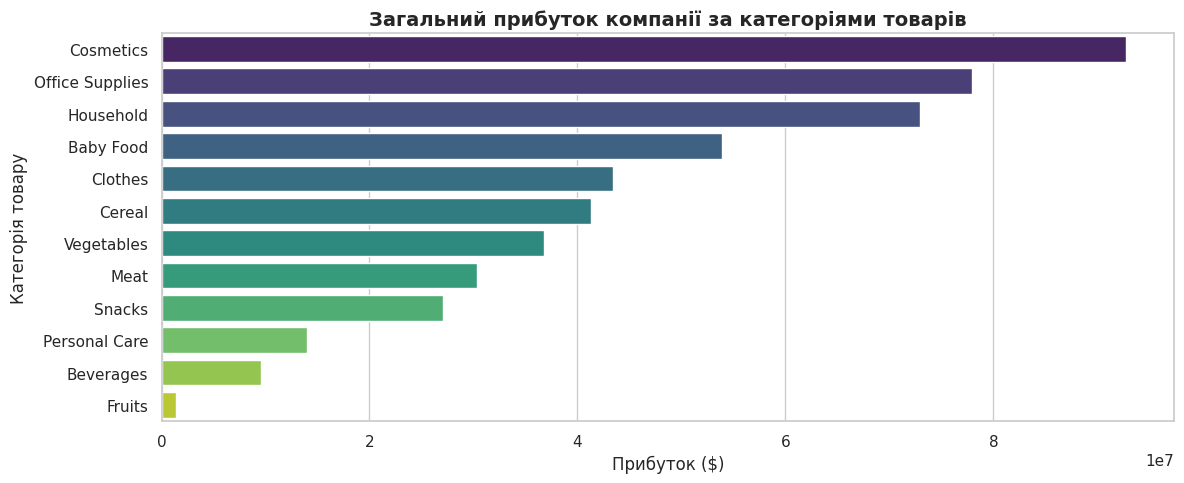

In [13]:
# 1.АНАЛІЗ ЗА КАТЕГОРІЯМИ ТОВАРІВ (item_type)
category_profit = df.groupby('item_type')['Profit'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=category_profit, x='Profit', y='item_type', hue='item_type', palette='viridis', legend=False)
plt.title('Загальний прибуток компанії за категоріями товарів', fontsize=14, fontweight='bold')
plt.xlabel('Прибуток ($)', fontsize=12)
plt.ylabel('Категорія товару', fontsize=12)
plt.tight_layout()
plt.show()

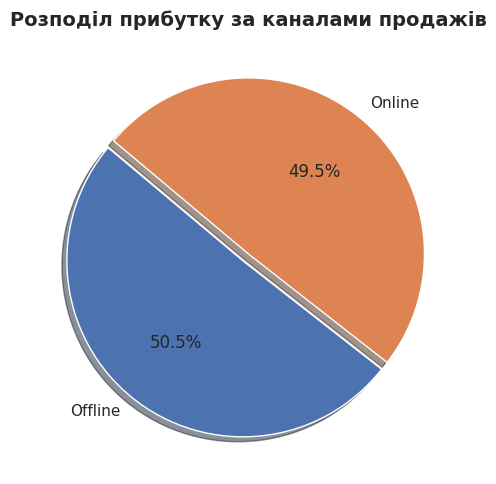

In [14]:
# 2. АНАЛІЗ ЗА КАНАЛАМИ ПРОДАЖУ (Sales Channel)
channel_analysis = df.groupby('Sales Channel')['Profit'].sum().reset_index()

plt.figure(figsize=(6, 5))
plt.pie(
    channel_analysis['Profit'],
    labels=channel_analysis['Sales Channel'],
    autopct='%1.1f%%',
    colors=['#4c72b0', '#dd8452'],
    startangle=140,
    explode=(0.05, 0),
    shadow=True
)

plt.title('Розподіл прибутку за каналами продажів', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

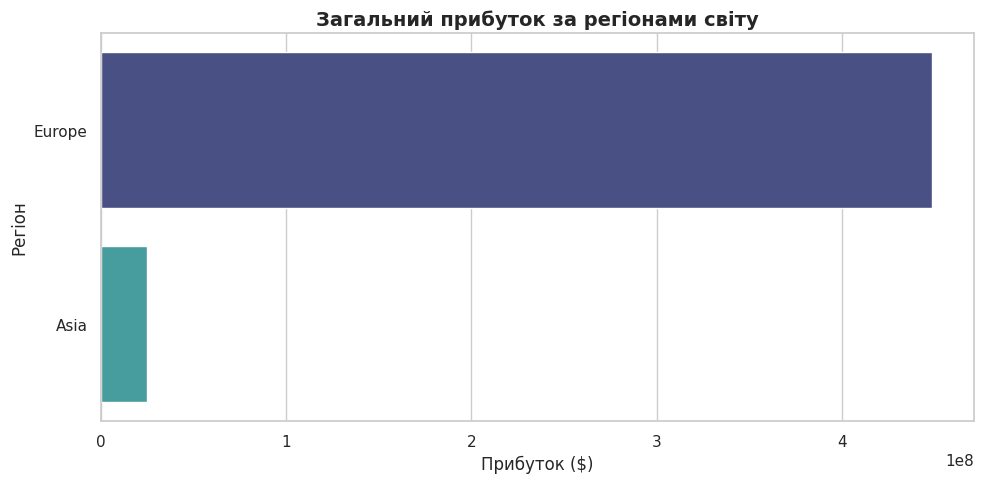

In [16]:
# 3. ГЕОГРАФІЧНИЙ АНАЛІЗ ЗА РЕГІОНАМИ (region)
region_profit = df[df['region'].notna()].groupby('region')['Profit'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=region_profit, x='Profit', y='region', hue='region', palette='mako', legend=False)
plt.title('Загальний прибуток за регіонами світу', fontsize=14, fontweight='bold')
plt.xlabel('Прибуток ($)', fontsize=12)
plt.ylabel('Регіон', fontsize=12)
plt.tight_layout()
plt.show()

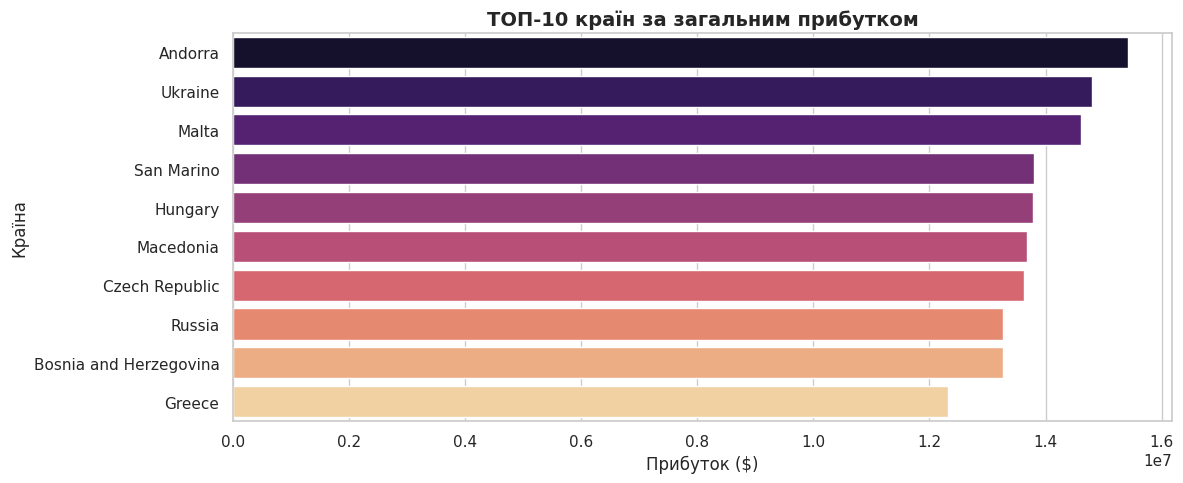

In [17]:
# 4. ГЕОГРАФІЧНИЙ АНАЛІЗ (ТОП-10 КРАЇН ЗА ПРИБУТКОМ)
top_countries = df[(df['name'].notna()) & (df['Country Code'] != 'Unknown')].groupby('name')['Profit'].sum().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=top_countries, x='Profit', y='name', hue='name', palette='magma', legend=False)
plt.title('ТОП-10 країн за загальним прибутком', fontsize=14, fontweight='bold')
plt.xlabel('Прибуток ($)', fontsize=12)
plt.ylabel('Країна', fontsize=12)
plt.tight_layout()
plt.show()

Структура продажів та прибутку


​1. Аналіз товарів
​Лідери: Найбільше прибутку компанії приносить Косметика (Cosmetics). Одразу за нею йдуть Офісне приладдя (Office Supplies) та Побутові товари (Household).
​Аутсайдери: Найменш прибутковими є Фрукти (Fruits) та Овочі (Vegetables).

​2. Канали продажів
​Прибуток ділиться майже порівну — близько 50% на 50% між інтернетом (Online) та звичайними магазинами (Offline).

​3. Географія
​Топ-3 найприбутковіші країни світу для компанії:
​Андорра (1-ше місце)
​Україна (2-ге місце)
​Мальта (3-тє місце)

In [18]:
# 1. Розраховуємо інтервал доставки в днях
df['Shipment Days'] = (df['Ship Date'] - df['Order Date']).dt.days

# Подивимось на базову статистику інтервалу (мінімум, максимум, середнє)
print("Статистика часу відвантаження (в днях):")
print(df['Shipment Days'].describe())

Статистика часу відвантаження (в днях):
count    1328.000000
mean       24.786898
std        14.586041
min         0.000000
25%        12.000000
50%        25.000000
75%        37.000000
max        50.000000
Name: Shipment Days, dtype: float64


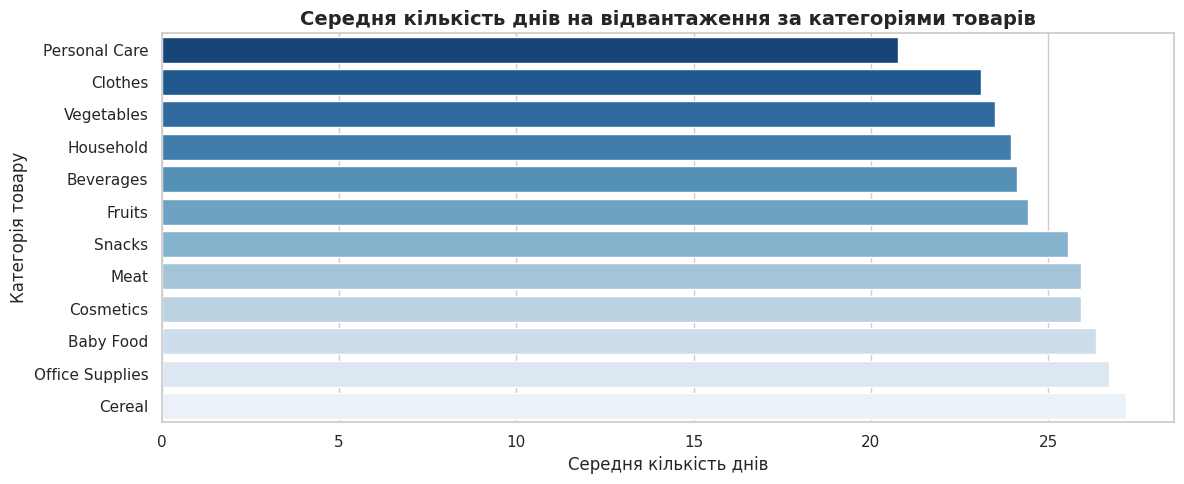

In [19]:
# Графік 1: Середній час відвантаження за КАТЕГОРІЯМИ ТОВАРІВ
cat_shipping = df.groupby('item_type')['Shipment Days'].mean().sort_values().reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=cat_shipping, x='Shipment Days', y='item_type', hue='item_type', palette='Blues_r', legend=False)
plt.title('Середня кількість днів на відвантаження за категоріями товарів', fontsize=14, fontweight='bold')
plt.xlabel('Середня кількість днів', fontsize=12)
plt.ylabel('Категорія товару', fontsize=12)
plt.tight_layout()
plt.show()

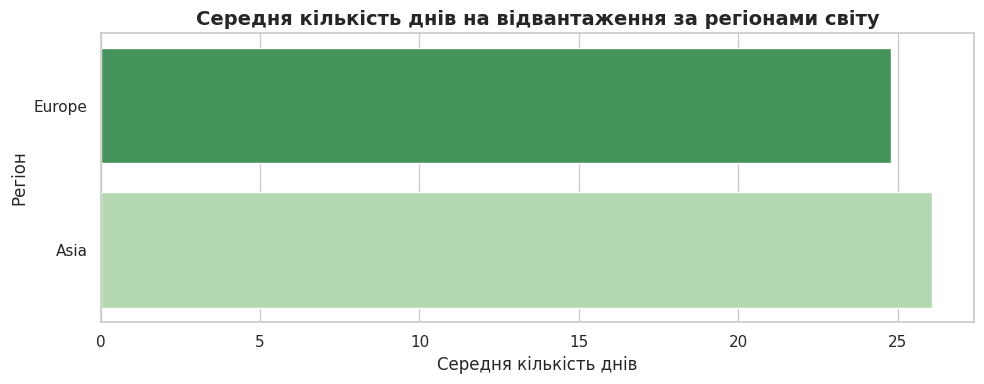

In [21]:
# Графік 2: Середній час відвантаження за РЕГІОНАМИ
region_shipping = df[df['region'].notna()].groupby('region')['Shipment Days'].mean().sort_values().reset_index()

plt.figure(figsize=(10, 4))
sns.barplot(data=region_shipping, x='Shipment Days', y='region', hue='region', palette='Greens_r', legend=False)
plt.title('Середня кількість днів на відвантаження за регіонами світу', fontsize=14, fontweight='bold')
plt.xlabel('Середня кількість днів', fontsize=12)
plt.ylabel('Регіон', fontsize=12)
plt.tight_layout()
plt.show()

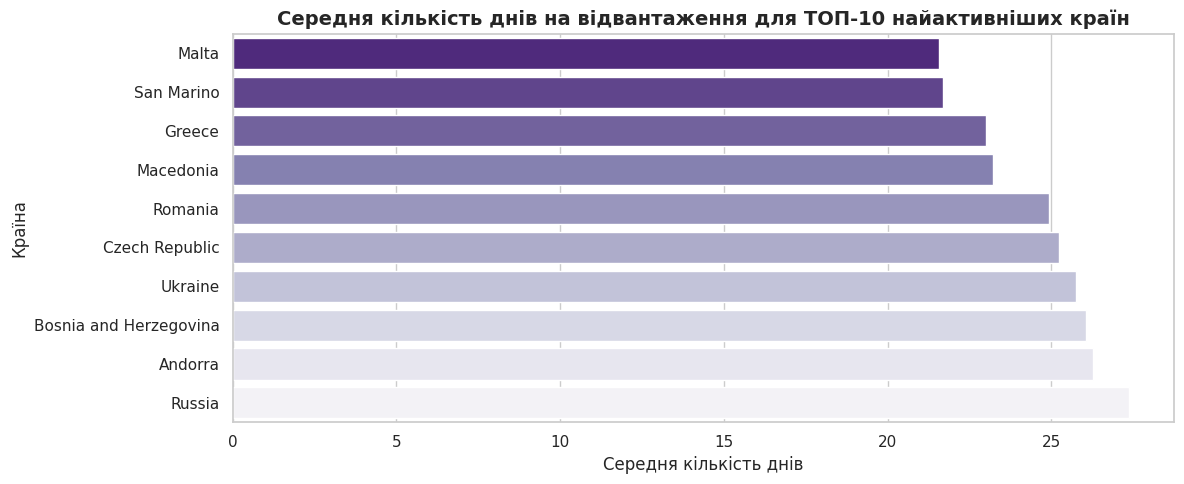

In [23]:

# Графік 3: Середній час відвантаження за КРАЇНАМИ (ТОП-10 за кількістю замовлень)
top_active_countries = df['name'].value_counts().head(10).index
country_shipping = df[df['name'].isin(top_active_countries)].groupby('name')['Shipment Days'].mean().sort_values().reset_index()

plt.figure(figsize=(12, 5))
sns.barplot(data=country_shipping, x='Shipment Days', y='name', hue='name', palette='Purples_r', legend=False)
plt.title('Середня кількість днів на відвантаження для ТОП-10 найактивніших країн', fontsize=14, fontweight='bold')
plt.xlabel('Середня кількість днів', fontsize=12)
plt.ylabel('Країна', fontsize=12)
plt.tight_layout()
plt.show()

Логістика та час відвантаження товарів (Shipment Days)

​1. Загальна статистика
​Мінімальний час: 0 днів (товар відвантажується в день замовлення).
​Максимальний час: 50 днів (майже два місяці, що є досить довгим терміном).
​Середній час відвантаження: ~25 днів (компанії в середньому потрібно трохи менше ніж місяць, щоб відправити замовлення).

​2. Аналіз за товарами
​Найповільніші: Найдовше зі складу відвантажуються Зернові (Cereal) та Офісне приладдя (Office Supplies).
​Найшвидші: Найшвидше готуються до відправки товари для Особистої гігієни (Personal Care).
 Офісне приладдя приносить нам один із найбільших прибутків, але водночас відвантажується дуже довго. Це слабке місце в логістиці, яке треба виправляти, щоб клієнти не йшли до конкурентів.

​3. Географія та регіони
​Регіони: Найповільніше замовлення відвантажуються в Азію (в середньому понад 26 днів), а найшвидше — в Європу (близько 24-25 днів).
​Країни-лідери: Серед 10 найактивніших країн найдовший час очікування в Росії та нашій топовій Андоррі. Україна також має високий показник очікування.

In [24]:
# Рахуємо коефіцієнт кореляції між днями доставки та прибутком на сирих (неагрегованих) даних
correlation = df['Shipment Days'].corr(df['Profit'])
print(f"Коефіцієнт кореляції між часом доставки та прибутком: {correlation:.4f}")

Коефіцієнт кореляції між часом доставки та прибутком: 0.0603


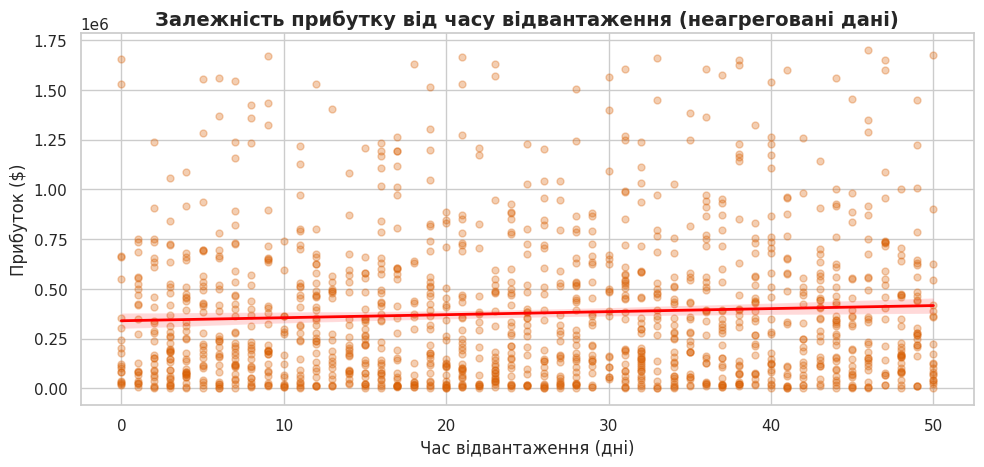

In [25]:
# Будуємо графік розсіювання (Scatter Plot) на всіх окремих замовленнях
plt.figure(figsize=(10, 5))
sns.regplot(
    data=df,
    x='Shipment Days',
    y='Profit',
    color='#d95f02',
    scatter_kws={'alpha': 0.3, 's': 25}, # прозорість та розмір точок для кращої читабельності
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Залежність прибутку від часу відвантаження (неагреговані дані)', fontsize=14, fontweight='bold')
plt.xlabel('Час відвантаження (дні)', fontsize=12)
plt.ylabel('Прибуток ($)', fontsize=12)
plt.tight_layout()
plt.show()




Аналіз залежності прибутку від часу відвантаження

 Коефіцієнт кореляції становить 0.0603. Лінія тренду має дуже  Прямого зв'язку між часом доставки та прибутком немає. Те, що товар доставляється довше, не означає, що він гарантовано принесе більше або менше прибутку. Проте великі й дорогі замовлення логічно потребують трохи більше часу на підготовку, через що лінія тренду злегка підіймається вгору на довших термінах.


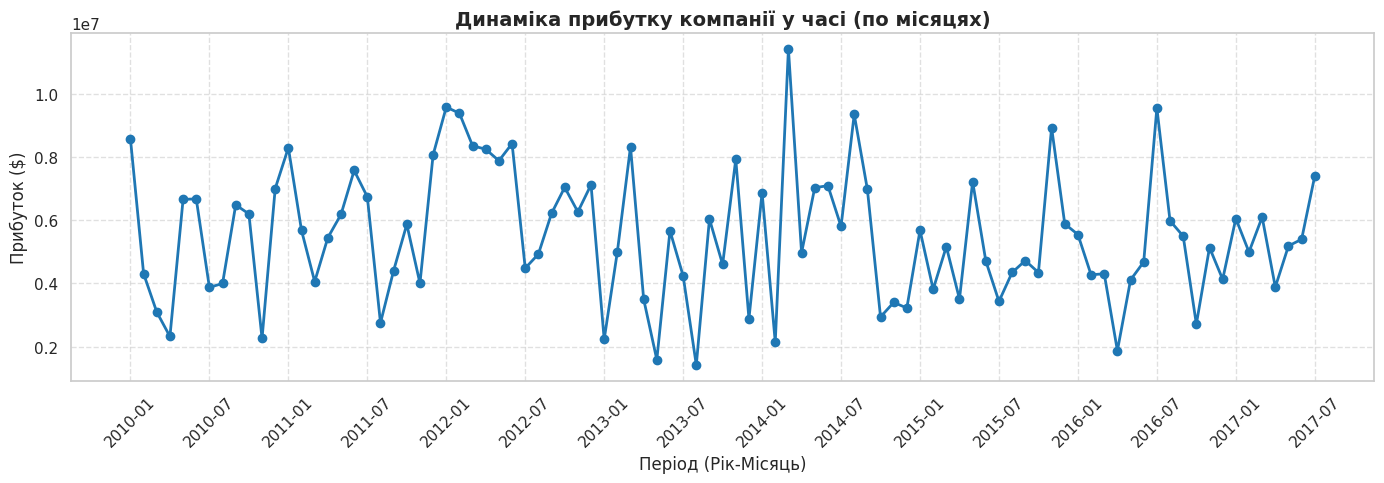

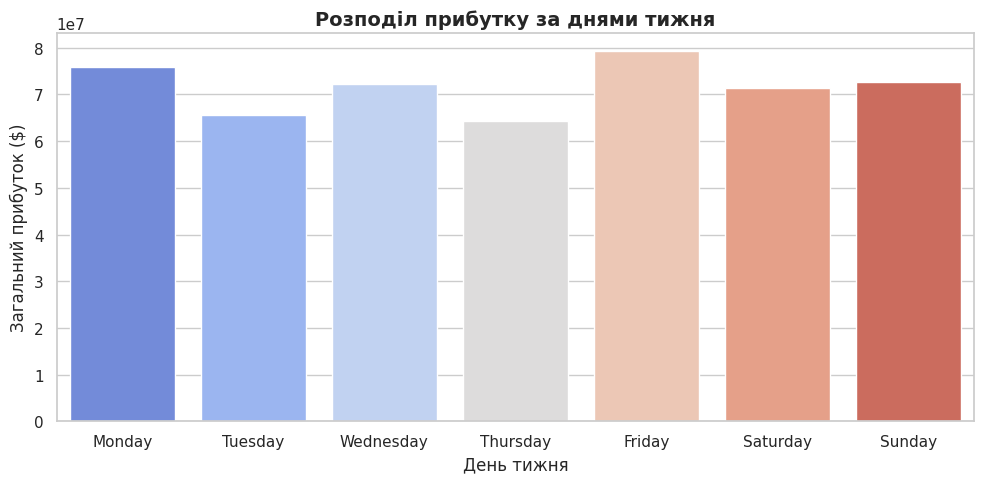

In [26]:
# 1. Створюємо колонку з назвою дня тижня
df['Order Day of Week'] = df['Order Date'].dt.day_name()

# Створюємо колонку з роком та місяцем для відстеження динаміки
df['Year_Month'] = df['Order Date'].dt.to_period('M')

# Графік 1: Динаміка загального прибутку по роках та місяцях

# Групуємо прибуток за роками та місяцями
timeline_profit = df.groupby('Year_Month')['Profit'].sum().reset_index()
timeline_profit['Year_Month'] = timeline_profit['Year_Month'].astype(str) # для графіку перетворимо на текст

plt.figure(figsize=(14, 5))
plt.plot(timeline_profit['Year_Month'], timeline_profit['Profit'], marker='o', color='#1f77b4', linewidth=2)
plt.title('Динаміка прибутку компанії у часі (по місяцях)', fontsize=14, fontweight='bold')
plt.xlabel('Період (Рік-Місяць)', fontsize=12)
plt.ylabel('Прибуток ($)', fontsize=12)
# Показуємо кожну 6-ту мітку на осі X, щоб графік не зливався
plt.xticks(ticks=range(0, len(timeline_profit), 6), labels=timeline_profit['Year_Month'].iloc[::6], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Графік 2: Аналіз продажів за днями тижня

# Групуємо прибуток за днями тижня та сортуємо їх у правильному порядку
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekly_profit = df.groupby('Order Day of Week')['Profit'].sum().reindex(days_order).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=weekly_profit, x='Order Day of Week', y='Profit', hue='Order Day of Week', palette='coolwarm', order=days_order, legend=False)
plt.title('Розподіл прибутку за днями тижня', fontsize=14, fontweight='bold')
plt.xlabel('День тижня', fontsize=12)
plt.ylabel('Загальний прибуток ($)', fontsize=12)
plt.tight_layout()
plt.show()



Динаміка продажів у часі та сезонність

​На графіку динаміки чітко видно регулярні щорічні сплески прибутку, які припадають на січень. Це сезонний пік продажів (імовірно, пов'язаний із новорічними закупками та початком бюджетного року у бізнес-клієнтів).


​ Аналіз продажів за днями тижня

 Найбільше прибутку компанія отримує у п'ятницю (1-ше місце) та понеділок (2-ге місце). Найменш прибутковим днем є четвер.
​

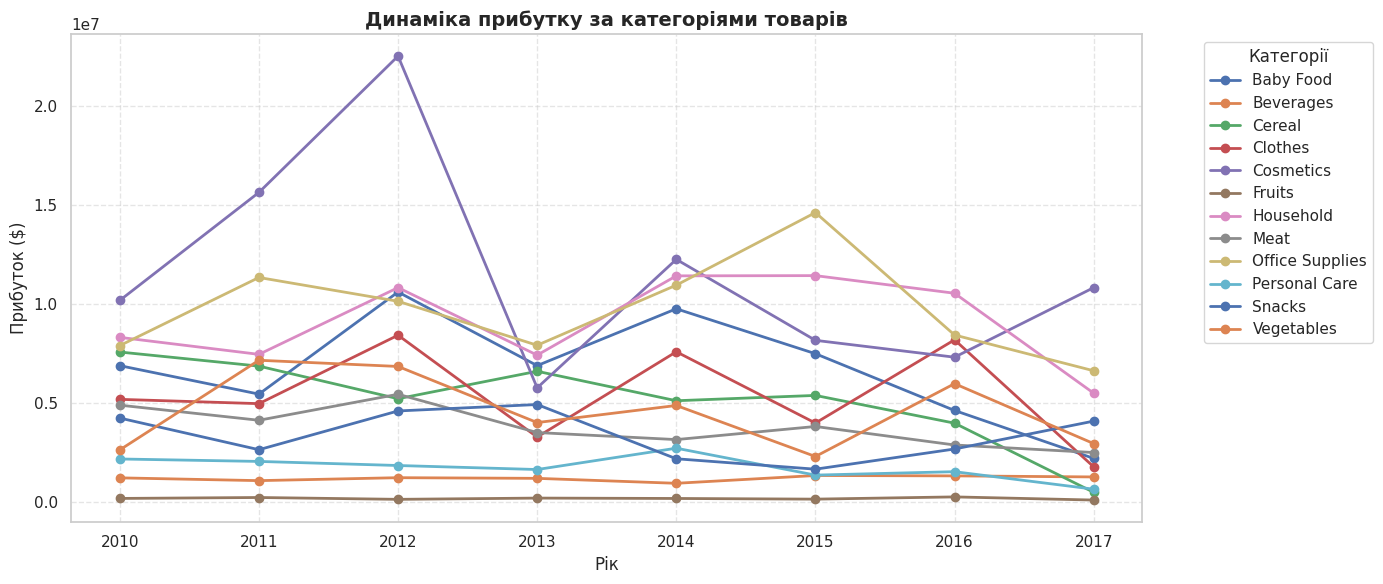

In [27]:
# Переконуємося, що рік є числовим полем
df['Year'] = df['Order Date'].dt.year

# А. Динаміка прибутку за КАТЕГОРІЯМИ ТОВАРІВ (по роках)
category_yearly = df.groupby(['Year', 'item_type'])['Profit'].sum().unstack().fillna(0)

plt.figure(figsize=(14, 6))
for column in category_yearly.columns:
    plt.plot(category_yearly.index, category_yearly[column], marker='o', label=column, linewidth=2)

plt.title('Динаміка прибутку за категоріями товарів', fontsize=14, fontweight='bold')
plt.xlabel('Рік', fontsize=12)
plt.ylabel('Прибуток ($)', fontsize=12)
plt.xticks(category_yearly.index)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Категорії")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Тенденція за категоріями: Продажі Косметики та Офісного приладдя демонструють стабільне зростання з роками.

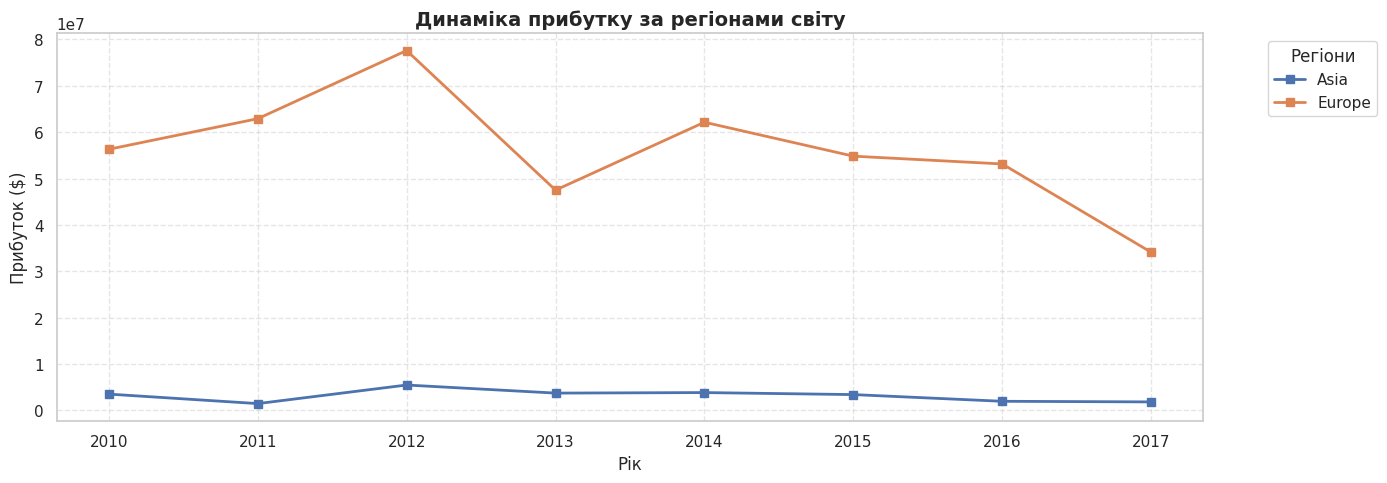

In [28]:

# Б. Динаміка прибутку за РЕГІОНАМИ
region_yearly = df[df['region'].notna()].groupby(['Year', 'region'])['Profit'].sum().unstack().fillna(0)

plt.figure(figsize=(14, 5))
for column in region_yearly.columns:
    plt.plot(region_yearly.index, region_yearly[column], marker='s', label=column, linewidth=2)

plt.title('Динаміка прибутку за регіонами світу', fontsize=14, fontweight='bold')
plt.xlabel('Рік', fontsize=12)
plt.ylabel('Прибуток ($)', fontsize=12)
plt.xticks(region_yearly.index)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Регіони")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

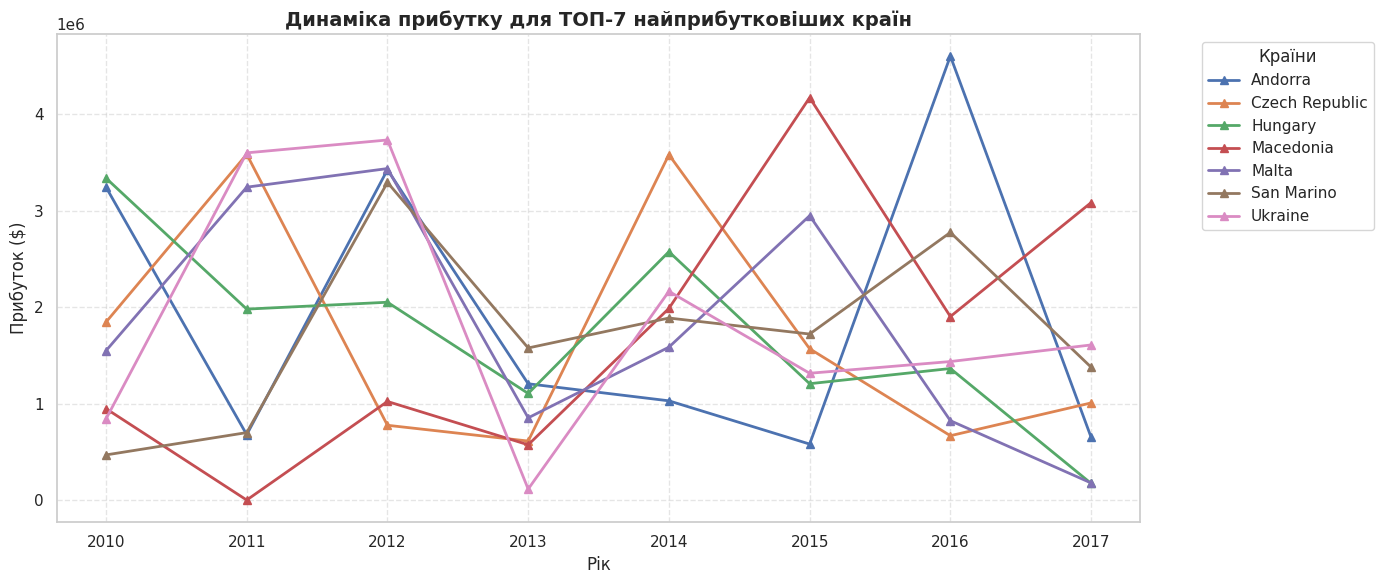

In [29]:
# В. Динаміка прибутку для ТОП-7 КРАЇН за загальним прибутком

# 1. Знаходимо ТОП-7 найприбутковіших країн (виключаючи Невідомі)
top7_countries = df[(df['name'].notna()) & (df['Country Code'] != 'Unknown')].groupby('name')['Profit'].sum().nlargest(7).index

# 2. Фільтруємо дані та групуємо за роками і країнами
country_yearly = df[df['name'].isin(top7_countries)].groupby(['Year', 'name'])['Profit'].sum().unstack().fillna(0)

# 3. Будуємо графік
plt.figure(figsize=(14, 6))
for column in country_yearly.columns:
    plt.plot(country_yearly.index, country_yearly[column], marker='^', label=column, linewidth=2)

plt.title('Динаміка прибутку для ТОП-7 найприбутковіших країн', fontsize=14, fontweight='bold')
plt.xlabel('Рік', fontsize=12)
plt.ylabel('Прибуток ($)', fontsize=12)
plt.xticks(country_yearly.index)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Країни")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


Аналіз за країнами: Графік показує, що навіть у межах лідерів (Андорра, Україна, Мальта тощо) прибуток коливається від року до року залежно від закупівлі великих партій товару. Проте загальний тренд для ключових ринків залишається стабільно високим протягом досліджуваного періоду.


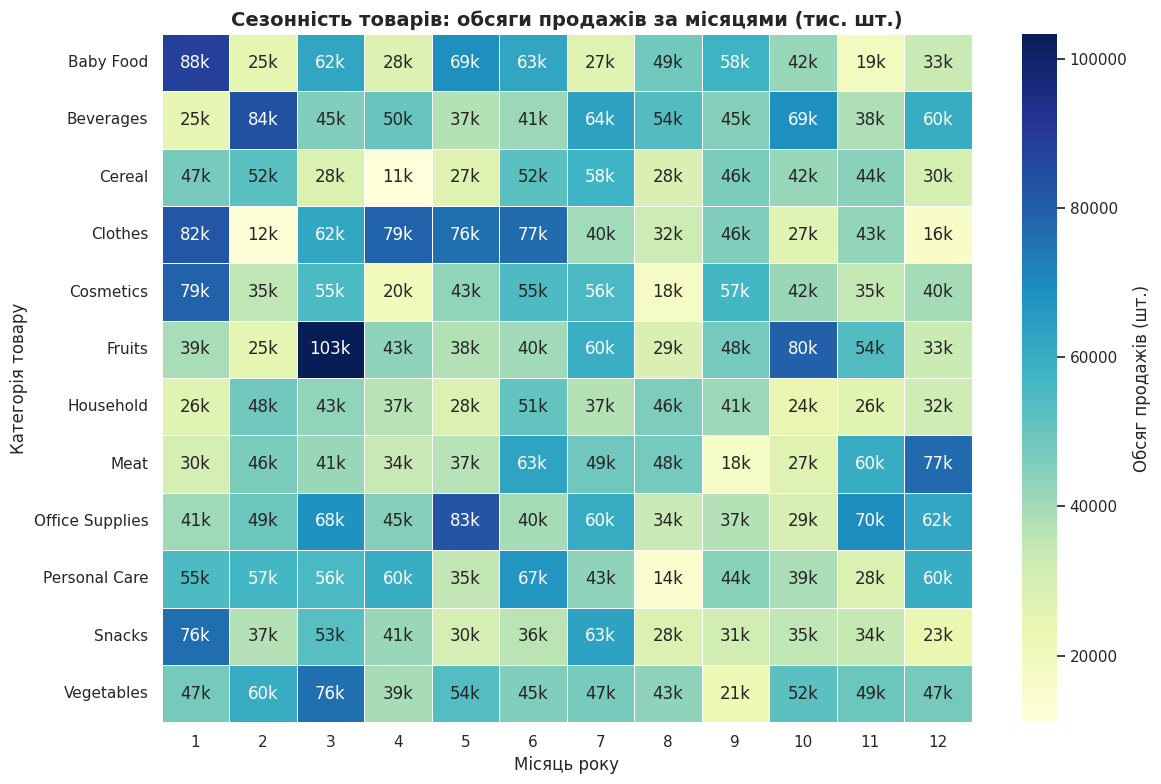

In [30]:
# 1. Створюємо колонку місяця
df['Month'] = df['Order Date'].dt.month

# 2. Рахуємо обсяги продажів у штуках для кожного товару по місяцях
product_seasonality = df.groupby(['item_type', 'Month'])['Units Sold'].sum().unstack(fill_value=0)

# 3. Створюємо текстову матрицю з форматом "Nk" (наприклад, 103k замість 103302)
annot_k = product_seasonality.map(lambda x: f"{x/1000:.0f}k" if x >= 1000 else f"{x}")

# 4. Будуємо Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    product_seasonality,
    annot=annot_k, # передаємо наші відформатовані підписи "Nk"
    fmt="", # вимикаємо стандартне форматування, бо вже підготували рядки
    cmap="YlGnBu",
    linewidths=.5,
    cbar_kws={'label': 'Обсяг продажів (шт.)'}
)

plt.title('Сезонність товарів: обсяги продажів за місяцями (тис. шт.)', fontsize=14, fontweight='bold')
plt.xlabel('Місяць року', fontsize=12)
plt.ylabel('Категорія товару', fontsize=12)
plt.tight_layout()

# Збереження та відображення
plt.savefig('seasonality_heatmap.png', dpi=300)
plt.show()


Фрукти (Fruits): Яскраво виражений сезонний товар. Пік продажів припадає на березень (понад 103 тис. шт.) та жовтень (близько 80 тис. шт.). У серпні та лютому продажі падають майже в 4 рази.
​Одяг (Clothes) & Косметика (Cosmetics): Мають високі продажі у січні та травні-червні (підготовка до літнього сезону та новорічні свята).
​М'ясо (Meat): Продажі різко зростають у грудні (77 тис. шт.) та червні (63 тис. шт.), що чітко збігається з періодами зимових свят та літнього сезону барбекю/пікніків.
​Офісне приладдя (Office Supplies): Має пік у травні та листопаді, що пов'язано з періодами корпоративних закупівель перед піврічними звітами.

**Загальний бізнес-висновок**

​1. *Фінансове здоров'я та позиціонування*
​Компанія демонструє наступнi фінансові показники: при загальному доході понад $1.7 млрд, чистий прибуток становить $501.4 млн. Рентабельність бізнесу сягає близько 29.4%, що свідчить про високу ефективність комерційної діяльності.
​Середній чек замовлення складає $1.28 млн. Це чітко вказує на те, що компанія фокусується на великому гурті (B2B сегмент) та працює з масштабними контрактами.

​2. *Продуктові та географічні драйвери прибутку*
​Косметика (Cosmetics) є абсолютним лідером і головним генератором грошового потоку. Одразу за нею йдуть Офісне приладдя (Office Supplies) та Побутові товари (Household). Натомість свіжі продукти (фрукти та овочі) мають найменшу маржинальність.
​У географічному розрізі трійку найприбутковіших ринків світу очолюють Андорра (1-ше місце), Україна (2-ге місце) та Мальта (3-тє місце).

​3. *Ефективність каналів збуту та сезонність*
​Бізнес має ідеально збалансовану омніканальну модель: прибуток розподіляється майже порівну (50% на 50%) між продажами через інтернет (Online) та традиційними поставками (Offline).
​В компанії яскраво виражена щорічна сезонність із піком у січні. Крім того, виявлено індивідуальну сезонність товарів: наприклад, продажі М'яса злітають у грудні та червні, а Фрукти мають чіткі піки у березні та жовтні.
​Найактивнішими днями для замовлень є п'ятниця та понеділок, тоді як четвер є найслабшим днем тижня.

​ *Головні ризики та слабкі місця в логістиці*
​Критична проблема: Середній час відвантаження товарів складає 25 днів, а максимум досягає 50 днів, що є дуже довгим терміном для B2B клієнтів.
​Що найважливіше — Офісне приладдя (наш топ-товар за прибутком) та країни-лідери (Андорра, Україна, Росія) мають найдовші затримки на складах. Прямої кореляції між часом доставки та прибутком немає (коефіцієнт 0.06), тобто клієнти чекають довго не тому, що замовлення занадто великі, а через внутрішні затримки логістики.

​ ***Стратегічні рекомендації для бізнесу ***

​Оптимізувати роботу складів для Топ-товарів: Необхідно терміново переглянути логістичні процеси для категорії Office Supplies та прискорити відвантаження замовлень в Андорру та Україну. Затримки на цих стратегічних ринках створюють ризик втрати ключових клієнтів.

​Управління продажами за днями тижня: Оскільки четвер є найслабшим днем, маркетингу рекомендується запускати спеціальні промо-акції або знижки саме в середу ввечері/четвер зранку, щоб штучно вирівняти тижневе навантаження. Понеділок та п'ятницю варто максимально завантажувати роботою менеджерів та менеджерів з логістики.

​Фокус на маржинальних товарах: Продовжувати інвестувати маркетинговий бюджет у просування Косметики та Офісних товарів, оскільки вони приносять компанії основні гроші, на відміну від низькорентабельних категорій (фрукти/овочі).
